In [1]:
import datetime, hashlib, json
from pathlib import Path
import pandas as pd
import torch
from plantdata import load_classes, read_manifest

EXPECTED = {"test_lab": "6c99ca503ff3e4e0", "test_wild": "8ab045da37da5bcb"}   # recorded by make_splits.py
RERUN_REASON = None      # leave None. Only if this notebook must run again (e.g. a crash), write why: it is logged

# 1. the test sets must be exactly the ones fixed before any experiment
for split, expected in EXPECTED.items():
    part = pd.read_csv(f"splits_v2/{split}.csv")
    key = "\n".join(sorted(f"{d}|{r}|{c}" for d, r, c in zip(part.dataset, part.rel_path, part.class_id)))
    got = hashlib.sha256(key.encode("utf-8")).hexdigest()[:16]
    print(f"{split:9s} {len(part):5d} images | fingerprint {got} | {'OK' if got == expected else 'DIFFERENT'}")
    if got != expected:
        raise RuntimeError(f"{split} is not the test set fixed before the experiments - stop and check.")

# 2. the test is run once: every run is written to a log that goes into the submission
OUT = Path("results/final_test")
OUT.mkdir(parents=True, exist_ok=True)
log = OUT / "RUN_LOG.txt"
if log.exists() and RERUN_REASON is None:
    raise RuntimeError(f"The final test has already been run (see {log}). Set RERUN_REASON to run it again.")
with log.open("a", encoding="utf-8") as f:
    f.write(f"{datetime.datetime.now().isoformat(timespec='seconds')}  "
            f"{'first run' if RERUN_REASON is None else 'rerun: ' + RERUN_REASON}\n")
print(log.read_text(encoding="utf-8"))

# 3. what the test sets contain
class_ids, crops, crop_mask = load_classes("splits_v2")
CACHE_DIR = Path("cache_256")
manifest = read_manifest(CACHE_DIR)
for split in EXPECTED:
    missing = len(pd.read_csv(f"splits_v2/{split}.csv")) - (manifest.split == split).sum()
    print(f"{split}: {'all images cached' if missing == 0 else f'{missing} images missing from the cache'}")
print(manifest[manifest.split.isin(EXPECTED)].groupby(["split", "dataset", "source_split"]).size().to_string())

test_lab   3950 images | fingerprint 6c99ca503ff3e4e0 | OK
test_wild  1909 images | fingerprint 8ab045da37da5bcb | OK
2026-10-30T14:23:40  first run

test_lab: all images cached
test_wild: all images cached
split      dataset       source_split
test_lab   PlantVillage  all             3950
test_wild  PlantWild     v1               537
                         v2              1372


In [2]:
import time
import joblib
import numpy as np
import open_clip
from baseline import masked_predict, select
from calibration import collect_logits
from features import save_split
from plantdata import PlantDataset, eval_transform, make_loader
from plantmodel import CropMaskedResNet
from zeroshot import image_features, text_features, zero_shot_logits

device = "cuda" if torch.cuda.is_available() else "cpu"
SPLITS = ["test_lab", "test_wild"]
ANN_RUNS = ["R01", "R15", "R21", "R22"]
T = json.loads(Path("checkpoints/R15_calibration.json").read_text())["temperature"]
chosen = json.loads(Path("checkpoints/q6_prompts.json").read_text())["chosen"]
CLIP_SOURCES = {"OpenCLIP": ("ViT-B-16", "laion2b_s34b_b88k"), "BioCLIP": ("hf-hub:imageomics/bioclip", None)}
class_crops = [crops[int(crop_mask[:, k].nonzero())] for k in range(len(class_ids))]

datasets = {s: PlantDataset(manifest, s, CACHE_DIR, crops, eval_transform()) for s in SPLITS}
pred = {s: datasets[s].info.reset_index(drop=True).assign(true=datasets[s].labels.numpy()) for s in SPLITS}
r15_probs = {}
seconds = {}

# 1. classical baseline C04 (features computed now; features/test_*.npz come from test photos: never submitted)
clf = joblib.load("checkpoints/C04.joblib")
start = time.perf_counter()
for s in SPLITS:
    X = save_split(datasets[s], s)
    pred[s]["C04"] = masked_predict(clf, select(X, "all"), datasets[s].crop_idx.numpy(), crop_mask.numpy())
seconds["C04"] = time.perf_counter() - start

# 2. the ANNs: the initial model and the three seeds of the final recipe
for run in ANN_RUNS:
    start = time.perf_counter()
    ck = torch.load(f"checkpoints/{run}.pt", map_location="cpu", weights_only=False)
    model = CropMaskedResNet(ck["config"]["depth"], crop_mask, pretrained=False)
    model.load_state_dict(ck["state_dict"])
    model.to(device).eval()
    for s in SPLITS:
        logits, _ = collect_logits(model, make_loader(datasets[s], 128, train=False, num_workers=0), device)
        pred[s][run] = logits.argmax(dim=1).numpy()
        if run == "R15":
            r15_probs[s] = (logits / T).softmax(dim=1)          # calibrated, as in the app
    seconds[run] = time.perf_counter() - start

# 3. zero-shot CLIP models with the prompts fixed on validation
for name, (arch, weights) in CLIP_SOURCES.items():
    start = time.perf_counter()
    m, _, preprocess = open_clip.create_model_and_transforms(arch, pretrained=weights)
    clip = {"model": m.to(device).eval(), "preprocess": preprocess, "tokenizer": open_clip.get_tokenizer(arch)}
    txt = text_features(clip, class_ids, class_crops, chosen[name], device).cpu()
    scale = m.logit_scale.detach().exp().item()
    for s in SPLITS:
        img = image_features(clip, datasets[s].paths, device)
        logits = zero_shot_logits(img, txt, datasets[s].crop_idx, crop_mask, scale)
        pred[s][name] = logits.argmax(dim=1).numpy()
    seconds[name] = time.perf_counter() - start
    del m, clip                                              # free the GPU before the next model
    if device == "cuda":
        torch.cuda.empty_cache()

for s in SPLITS:
    pred[s].to_csv(OUT / f"predictions_{s}.csv", index=False)
    torch.save(r15_probs[s], OUT / f"R15_calibrated_probs_{s}.pt")
models = ["C04"] + ANN_RUNS + list(CLIP_SOURCES)
print({k: f"{v:.0f} s" for k, v in seconds.items()})
print(pd.DataFrame({s: [len(pred[s])] + [int((pred[s][m] == pred[s].true).sum()) for m in models]
                    for s in SPLITS}, index=["photos"] + [f"{m} correct" for m in models]).to_string())

{'C04': '51 s', 'R01': '17 s', 'R15': '14 s', 'R21': '13 s', 'R22': '14 s', 'OpenCLIP': '31 s', 'BioCLIP': '36 s'}
                  test_lab  test_wild
photos                3950       1909
C04 correct           3720        594
R01 correct           3705        788
R15 correct           3829        954
R21 correct           3852        911
R22 correct           3797        969
OpenCLIP correct      1862       1032
BioCLIP correct       1604        852


In [3]:
from training import scores

B = 2000                                     # bootstrap resamples
MODELS = ["C04", "R01", "R15", "R21", "R22", "OpenCLIP", "BioCLIP"]
SEEDS = ["R15", "R21", "R22"]                # the final ANN recipe
disease = np.array([not c.endswith("_healthy") for c in class_ids])
K = len(class_ids)

def macro_f1(y, p, keep):
    """Macro-F1 over the classes in `keep`, from a confusion count (fast enough for thousands of resamples)."""
    cm = np.bincount(y * K + p, minlength=K * K).reshape(K, K)
    tp = np.diag(cm)
    f1 = np.divide(2 * tp, cm.sum(0) + cm.sum(1), out=np.zeros(K), where=(cm.sum(0) + cm.sum(1)) > 0)
    return f1[keep].mean()

rng = np.random.default_rng(42)
rows, diffs = [], []
for s in SPLITS:
    df = pred[s]
    y = df.true.to_numpy()
    n = len(y)
    # random within crop: 200 sets of random guesses, each guess uniform over the photo's crop classes
    allowed = crop_mask.numpy()[[crops.index(c) for c in df.crop]]
    guesses = [np.array([rng.choice(np.flatnonzero(a)) for a in allowed]) for _ in range(200)]
    r16 = [macro_f1(y, g, disease) for g in guesses]
    r20 = [macro_f1(y, g, np.ones(K, bool)) for g in guesses]
    rows.append({"split": s, "model": "random within crop", "F1-16": np.mean(r16),
                 "F1-16 95% CI": f"{np.percentile(r16, 2.5):.3f}–{np.percentile(r16, 97.5):.3f}",
                 "F1-20": np.mean(r20), "LB recall": np.nan, "accuracy": np.mean([(g == y).mean() for g in guesses])})

    # every model: point scores, and the same 2000 resamples of photos for all (paired comparison)
    idx = rng.integers(0, n, size=(B, n))
    boot = {m: np.array([macro_f1(y[i], df[m].to_numpy()[i], disease) for i in idx]) for m in MODELS}
    boot["final ANN (3 seeds)"] = np.mean([boot[m] for m in SEEDS], axis=0)
    for m in MODELS + ["final ANN (3 seeds)"]:
        runs = SEEDS if m == "final ANN (3 seeds)" else [m]
        per_run = pd.DataFrame([scores(y, df[r], class_ids) for r in runs])
        row = {"split": s, "model": m, "F1-16": per_run.macro_f1_16_disease.mean(),
               "F1-16 95% CI": f"{np.percentile(boot[m], 2.5):.3f}–{np.percentile(boot[m], 97.5):.3f}",
               "F1-20": per_run.macro_f1_20.mean(), "LB recall": per_run.late_blight_recall.mean(),
               "accuracy": per_run.accuracy.mean()}
        if len(runs) > 1:
            row["seed spread (sd)"] = per_run.macro_f1_16_disease.std()
        rows.append(row)
    # paired differences: final ANN (3-seed mean) minus each other model, on the same resamples
    for m in ["C04", "R01", "OpenCLIP", "BioCLIP"]:
        d = boot["final ANN (3 seeds)"] - boot[m]
        diffs.append({"split": s, "comparison": f"final ANN − {m}", "difference in F1-16": d.mean(),
                      "95% CI": f"{np.percentile(d, 2.5):+.3f} to {np.percentile(d, 97.5):+.3f}",
                      "share of resamples where the ANN is better": f"{(d > 0).mean():.0%}"})

table = pd.DataFrame(rows).round(3)
diff_table = pd.DataFrame(diffs).round(3)
table.to_csv(OUT / "scores_with_ci.csv", index=False)
diff_table.to_csv(OUT / "paired_differences.csv", index=False)
for s in SPLITS:
    print(f"\n{s}\n" + table[table.split == s].drop(columns="split").to_string(index=False))
print("\n" + diff_table.to_string(index=False))


test_lab
              model  F1-16 F1-16 95% CI  F1-20  LB recall  accuracy  seed spread (sd)
 random within crop  0.264  0.250–0.281  0.284        NaN     0.252               NaN
                C04  0.931  0.921–0.939  0.941      0.895     0.942               NaN
                R01  0.921  0.909–0.931  0.930      0.974     0.938               NaN
                R15  0.954  0.944–0.963  0.962      0.986     0.969               NaN
                R21  0.969  0.961–0.976  0.974      0.991     0.975               NaN
                R22  0.938  0.927–0.948  0.948      0.972     0.961               NaN
           OpenCLIP  0.335  0.323–0.347  0.421      0.518     0.471               NaN
            BioCLIP  0.378  0.362–0.394  0.434      0.236     0.406               NaN
final ANN (3 seeds)  0.954  0.945–0.961  0.961      0.983     0.969             0.016

test_wild
              model  F1-16 F1-16 95% CI  F1-20  LB recall  accuracy  seed spread (sd)
 random within crop  0.248  0.226

In [4]:
from sklearn.metrics import f1_score
from calibration import expected_calibration_error

# 1. calibration on the test sets: the temperature was fitted on val_wild only
cal_rows = []
for s in SPLITS:
    y = torch.tensor(pred[s].true.to_numpy())
    calibrated = r15_probs[s]
    raw = (T * calibrated.clamp_min(1e-30).log()).softmax(dim=1)     # undo the temperature: softmax(logits)
    for name, p in [("before (T = 1)", raw), (f"after (T = {T:.2f})", calibrated)]:
        cal_rows.append({"split": s, "R15 probabilities": name, "mean confidence": float(p.max(1).values.mean()),
                         "accuracy": float((p.argmax(1) == y).float().mean()),
                         "ECE": expected_calibration_error(p, y)})
calibration = pd.DataFrame(cal_rows).round(3)
calibration.to_csv(OUT / "calibration_test.csv", index=False)
print(calibration.to_string(index=False))

# 2. errors by class on test_wild: F1 per class, and where each class's photos go
df = pred["test_wild"]
y = df.true.to_numpy()
train_counts = pd.read_csv("splits_v2/train.csv").class_id.value_counts()
per_class = pd.DataFrame({"class": class_ids, "test photos": np.bincount(y, minlength=K),
                          "train photos (lab)": [int(train_counts.get(c, 0)) for c in class_ids]})
per_class["final ANN (3 seeds)"] = np.mean([f1_score(y, df[r], labels=range(K), average=None, zero_division=0)
                                           for r in SEEDS], axis=0)
for m in ["OpenCLIP", "BioCLIP", "C04"]:
    per_class[m] = f1_score(y, df[m], labels=range(K), average=None, zero_division=0)
top_wrong = []
for k in range(K):
    wrong = df[(df.true == k) & (df.R15 != k)].R15.value_counts()
    top_wrong.append(f"{class_ids[wrong.index[0]]} ({wrong.iloc[0]})" if len(wrong) else "–")
per_class["R15's most common mistake"] = top_wrong
per_class = per_class.round(3).sort_values("final ANN (3 seeds)")
per_class.to_csv(OUT / "per_class_test_wild.csv", index=False)
print("\n" + per_class.to_string(index=False))

# 3. errors by crop and by PlantWild source (v1 = healthy classes, v2 = disease classes)
groups = []
for col in ["crop", "source_split"]:
    for value, part in df.groupby(col):
        yy = part.true.to_numpy()
        row = {"group": f"{col} = {value}", "photos": len(part)}
        for m in ["final ANN (3 seeds)", "OpenCLIP", "BioCLIP"]:
            runs = SEEDS if m.startswith("final") else [m]
            row[f"{m} accuracy"] = np.mean([(part[r].to_numpy() == yy).mean() for r in runs])
        groups.append(row)
by_group = pd.DataFrame(groups).round(3)
by_group.to_csv(OUT / "by_crop_and_source_test_wild.csv", index=False)
print("\n" + by_group.to_string(index=False))

    split R15 probabilities  mean confidence  accuracy   ECE
 test_lab    before (T = 1)            0.968     0.969 0.004
 test_lab  after (T = 3.47)            0.697     0.969 0.273
test_wild    before (T = 1)            0.786     0.500 0.286
test_wild  after (T = 3.47)            0.507     0.500 0.027

                    class  test photos  train photos (lab)  final ANN (3 seeds)  OpenCLIP  BioCLIP   C04      R15's most common mistake
           tomato_healthy          141                1114                0.054     0.687    0.289 0.000        tomato_late_blight (84)
      tomato_mosaic_virus           56                 261                0.078     0.171    0.105 0.092        tomato_late_blight (24)
    tomato_bacterial_spot           71                1488                0.095     0.260    0.085 0.025 tomato_septoria_leaf_spot (36)
         tomato_leaf_mold          138                 664                0.269     0.347    0.107 0.142       tomato_late_blight (100)
       tomato_

model                               R15 (deployed)  final ANN (3 seeds)  OpenCLIP  BioCLIP    R01    C04
right action                                 0.663                0.658     0.694    0.609  0.623  0.517
diseased → 'no action'                       0.012                0.010     0.007    0.028  0.009  0.029
healthy → told to treat                      0.503                0.533     0.246    0.600  0.581  0.797
healthy → urgent late-blight alarm           0.156                0.160     0.002    0.063  0.184  0.128
virus → told to use fungicide                0.553                0.672     0.106    0.642  0.813  0.756
late blight caught (recall)                  0.828                0.781     0.633    0.651  0.870  0.349
late-blight alarms that were right           0.312                0.324     0.446    0.472  0.280  0.230

rank correlation, lab training photos vs final ANN field F1, over 20 classes: -0.29


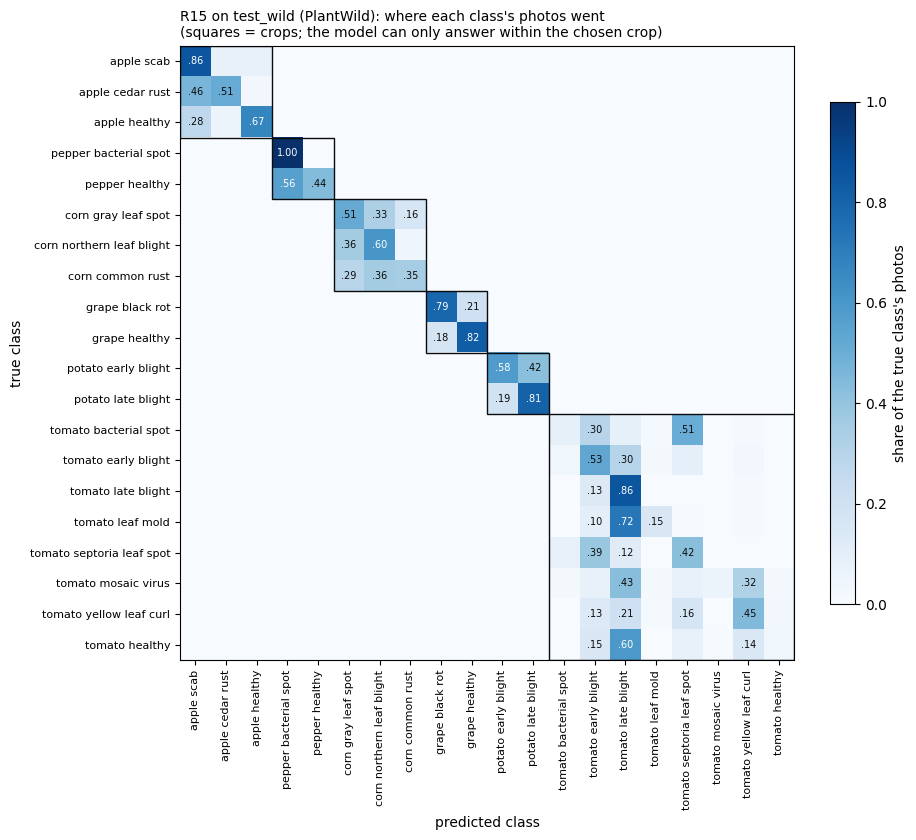

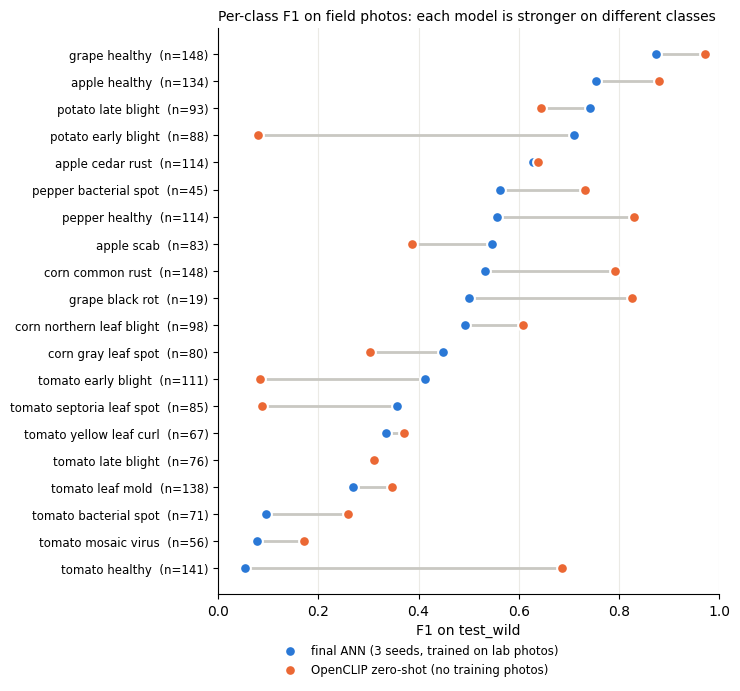

In [5]:
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

# 1. from class to the officer's action (the same types as the app)
TYPE = {"apple_scab": "fungal", "apple_cedar_rust": "fungal", "apple_healthy": "healthy",
        "pepper_bacterial_spot": "bacterial", "pepper_healthy": "healthy",
        "corn_gray_leaf_spot": "fungal", "corn_northern_leaf_blight": "fungal", "corn_common_rust": "fungal",
        "grape_black_rot": "fungal", "grape_healthy": "healthy",
        "potato_early_blight": "fungal", "potato_late_blight": "oomycete",
        "tomato_bacterial_spot": "bacterial", "tomato_early_blight": "fungal", "tomato_late_blight": "oomycete",
        "tomato_leaf_mold": "fungal", "tomato_septoria_leaf_spot": "fungal", "tomato_mosaic_virus": "viral",
        "tomato_yellow_leaf_curl": "viral", "tomato_healthy": "healthy"}
kind = np.array([TYPE[c] for c in class_ids])

def share(hits):
    """The share of True values (empty -> not defined)."""
    return hits.mean() if len(hits) else np.nan

def action_errors(true, guess):
    t, g = kind[true], kind[guess]
    return {"right action": share(t == g),
            "diseased → 'no action'": share(g[t != "healthy"] == "healthy"),
            "healthy → told to treat": share(g[t == "healthy"] != "healthy"),
            "healthy → urgent late-blight alarm": share(g[t == "healthy"] == "oomycete"),
            "virus → told to use fungicide": share(np.isin(g[t == "viral"], ["fungal", "oomycete"])),
            "late blight caught (recall)": share(g[t == "oomycete"] == "oomycete"),
            "late-blight alarms that were right": share(t[g == "oomycete"] == "oomycete")}

rows = []
for m in ["R15", "final ANN (3 seeds)", "OpenCLIP", "BioCLIP", "R01", "C04"]:
    runs = SEEDS if m.startswith("final") else [m]
    row = pd.DataFrame([action_errors(y, df[r].to_numpy()) for r in runs]).mean()
    rows.append({"model": m + (" (deployed)" if m == "R15" else ""), **row.round(3).to_dict()})
actions = pd.DataFrame(rows)
actions.to_csv(OUT / "action_errors_test_wild.csv", index=False)
print(actions.set_index("model").T.to_string())

# 2. do classes with more lab training photos do better in the field?
rho = spearmanr(per_class["train photos (lab)"], per_class["final ANN (3 seeds)"]).statistic
print(f"\nrank correlation, lab training photos vs final ANN field F1, over 20 classes: {rho:.2f}")

# 3. figure: R15's confusion matrix on test_wild (rows = true class, each row sums to 1)
cm = np.zeros((K, K))
np.add.at(cm, (y, df["R15"].to_numpy()), 1)
cm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
names = [c.replace("_", " ") for c in class_ids]
fig, ax = plt.subplots(figsize=(9.5, 8.5))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
for i in range(K):
    for j in range(K):
        if cm[i, j] >= 0.10:
            ax.text(j, i, f"{cm[i, j]:.2f}".lstrip("0"), ha="center", va="center", fontsize=7,
                    color="white" if cm[i, j] > 0.55 else "#0b0b0b")
edges = [k - 0.5 for k in range(K + 1) if k == K or k == 0 or class_crops[k] != class_crops[k - 1]]
for a, b in zip(edges, edges[1:]):
    ax.add_patch(plt.Rectangle((a, a), b - a, b - a, fill=False, ec="#0b0b0b", lw=1))
ax.set_xticks(range(K), names, rotation=90, fontsize=8)
ax.set_yticks(range(K), names, fontsize=8)
ax.set_xlabel("predicted class")
ax.set_ylabel("true class")
fig.colorbar(im, ax=ax, fraction=0.035, label="share of the true class's photos")
ax.set_title("R15 on test_wild (PlantWild): where each class's photos went\n(squares = crops; the model can only "
             "answer within the chosen crop)", fontsize=10, loc="left")
fig.tight_layout()
fig.savefig("figures/final_confusion_test_wild.png", dpi=200, bbox_inches="tight")

# 4. figure: F1 per class, final ANN vs OpenCLIP (the two models the test could not separate overall)
order = per_class.sort_values("final ANN (3 seeds)")
fig, ax = plt.subplots(figsize=(7.5, 7))
ypos = np.arange(len(order))
ax.hlines(ypos, order["final ANN (3 seeds)"], order["OpenCLIP"], color="#c9c8c2", lw=2, zorder=1)
ax.scatter(order["final ANN (3 seeds)"], ypos, s=60, color="#2a78d6", edgecolor="white", lw=1.5, zorder=3,
           label="final ANN (3 seeds, trained on lab photos)")
ax.scatter(order["OpenCLIP"], ypos, s=60, color="#eb6834", edgecolor="white", lw=1.5, zorder=3,
           label="OpenCLIP zero-shot (no training photos)")
ax.set_yticks(ypos, [f"{c.replace('_', ' ')}  (n={n})" for c, n in zip(order["class"], order["test photos"])],
              fontsize=8.5)
ax.set_xlim(0, 1)
ax.set_xlabel("F1 on test_wild")
ax.grid(axis="x", color="#ebeae5", lw=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, fontsize=8.5, loc="upper center", bbox_to_anchor=(0.4, -0.07), ncol=1)
ax.set_title("Per-class F1 on field photos: each model is stronger on different classes", fontsize=10, loc="left")
fig.tight_layout()
fig.savefig("figures/final_per_class_test_wild.png", dpi=200, bbox_inches="tight")

In [6]:
import re
from sklearn.metrics import roc_auc_score
from ood import PathDataset, familiarity_scores, raw_logits
from zeroshot import CROP_TEXT

# out of scope, never used before: PlantWild photos of classes outside the 20 (no class_id in the audit index)
index = pd.read_csv("audit_outputs/image_index.csv")
fresh = index[index.dataset.isin(["plantwild_v1", "plantwild_v2"]) & index.class_id.isna()].copy()
fresh["file"] = fresh.path.map(lambda p: Path(p).name)
fresh = fresh.drop_duplicates(subset=["folder", "file"])           # the same photo can be in both releases
fresh = fresh.sample(min(3000, len(fresh)), random_state=42).reset_index(drop=True)
CROP_WORDS = {"corn": r"corn|maize", "bell_pepper": r"pepper"}

def folder_crop(folder):
    """Which of our crops a PlantWild class belongs to (None = another plant)."""
    for c in crops:
        if re.search(rf"\b({CROP_WORDS.get(c, CROP_TEXT[c][0])})\b", folder.lower()):
            return c
    return None

n = len(fresh)
out_crop = torch.arange(len(crops)).repeat_interleave(n)          # every photo under every crop, as before
same = np.tile(fresh.folder.map(folder_crop).to_numpy(), len(crops)) == np.array(crops, dtype=object)[out_crop.numpy()]
print(f"{n} PlantWild photos from {fresh.folder.nunique()} classes outside the 20; "
      f"{same.sum()} (photo, crop) pairs are the right crop with a problem the model does not know")

in_paths = datasets["test_wild"].paths                              # in scope: the test_wild photos, own crop
in_crop = datasets["test_wild"].crop_idx
rows = []

def report(name, s_in, s_out, threshold):
    s_in, s_out = np.asarray(s_in, dtype=float), np.asarray(s_out, dtype=float)
    flagged = s_out < threshold
    rows.append({"warning": name,
                 "AUROC": roc_auc_score(np.r_[np.ones(len(s_in)), np.zeros(len(s_out))], np.r_[s_in, s_out]),
                 "in-scope kept": (s_in >= threshold).mean(),
                 "wrong crop: missed": 1 - flagged[~same].mean(),
                 "right crop, unknown problem: missed": 1 - flagged[same].mean() if same.any() else np.nan})

# 1. the ANN's warning, with the threshold fixed on validation (cell O1)
threshold = json.loads(Path("checkpoints/R15_ood.json").read_text())["threshold"]
ck = torch.load("checkpoints/R15.pt", map_location="cpu", weights_only=False)
ann = CropMaskedResNet(ck["config"]["depth"], crop_mask, pretrained=False)
ann.load_state_dict(ck["state_dict"])
ann.to(device).eval()
raw_in = raw_logits(ann, make_loader(PathDataset(in_paths, eval_transform()), 128, train=False, num_workers=0), device)
raw_out = raw_logits(ann, make_loader(PathDataset(fresh.path, eval_transform()), 128, train=False, num_workers=0), device)
report("R15 energy (deployed)", familiarity_scores(raw_in, in_crop, crop_mask, T)["energy"],
       familiarity_scores(raw_out.repeat(len(crops), 1), out_crop, crop_mask, T)["energy"], threshold)

# 2. the CLIP crop check, with the same prompts as G4 and its threshold from val_wild (keeps 95%)
GENERIC = ["a photo of a leaf of another plant.", "a photo of a fruit.", "a photo of a vegetable.",
           "a photo of a flower.", "a photo of soil.", "a photo of a person.", "a drawing or a page of text."]
scope_prompts = [f"a photo of a {CROP_TEXT[c][0]} leaf." for c in crops] + GENERIC
val_crop = torch.tensor([crops.index(c) for c in manifest[manifest.split == "val_wild"].crop])
for name, (arch, weights) in CLIP_SOURCES.items():
    m, _, preprocess = open_clip.create_model_and_transforms(arch, pretrained=weights)
    clip = {"model": m.to(device).eval(), "preprocess": preprocess}
    with torch.no_grad():
        txt = m.encode_text(open_clip.get_tokenizer(arch)(scope_prompts).to(device)).float()
    txt = (txt / txt.norm(dim=-1, keepdim=True)).cpu()
    scale = m.logit_scale.detach().exp().item()
    p_crop = lambda img, c: (scale * img @ txt.T).softmax(dim=1)[torch.arange(len(img)), c]
    val_threshold = float(np.quantile(p_crop(torch.load(f"features/clip_{name}_val_wild.pt"), val_crop), 0.05))
    s_in = p_crop(image_features(clip, in_paths, device), in_crop)
    s_out = p_crop(image_features(clip, fresh.path, device).repeat(len(crops), 1), out_crop)
    report(f"{name} crop check", s_in, s_out, val_threshold)
    del m, clip
    if device == "cuda":
        torch.cuda.empty_cache()

fresh_check = pd.DataFrame(rows).round(3)
fresh_check.to_csv(OUT / "scope_check_fresh_plantwild.csv", index=False)
print(fresh_check.to_string(index=False))

3000 PlantWild photos from 111 classes outside the 20; 257 (photo, crop) pairs are the right crop with a problem the model does not know
              warning  AUROC  in-scope kept  wrong crop: missed  right crop, unknown problem: missed
R15 energy (deployed)  0.682          0.957               0.836                                0.774
  OpenCLIP crop check  0.900          0.939               0.281                                0.833
   BioCLIP crop check  0.851          0.959               0.519                                0.984
